In [17]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, Dense
from sklearn.metrics import mean_squared_error, mean_absolute_error

print("TensorFlow Version:", tf.__version__)


TensorFlow Version: 2.21.0


In [18]:
# Create a sequence of time points
time = np.arange(0, 100, 0.1)

# Generate a sine-wave time series
data = np.sin(time)

print("Number of data points:", len(data))
print("First 10 values:", data[:10])


Number of data points: 1000
First 10 values: [0.         0.09983342 0.19866933 0.29552021 0.38941834 0.47942554
 0.56464247 0.64421769 0.71735609 0.78332691]


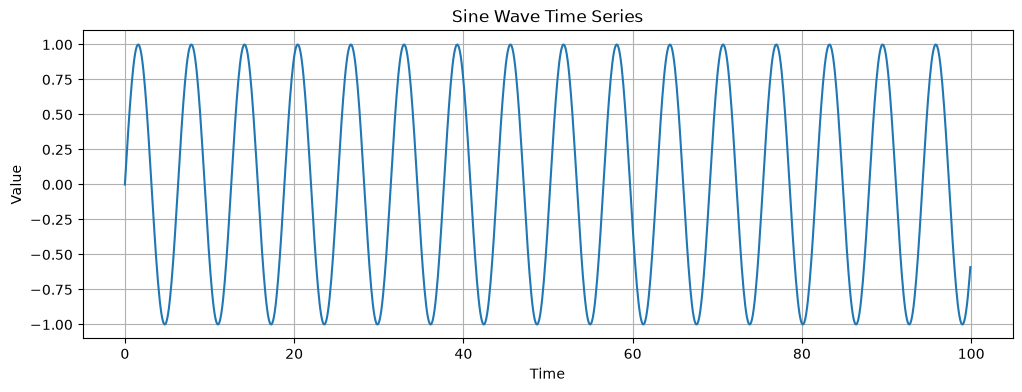

In [19]:
plt.figure(figsize=(12, 4))
plt.plot(time, data)
plt.title("Sine Wave Time Series")
plt.xlabel("Time")
plt.ylabel("Value")
plt.grid(True)
plt.show()


In [20]:
# Number of previous time steps used to predict the next value
sequence_length = 20

X = []
y = []

for i in range(len(data) - sequence_length):
    X.append(data[i:i + sequence_length])
    y.append(data[i + sequence_length])

X = np.array(X)
y = np.array(y)

print("X shape before reshaping:", X.shape)
print("y shape:", y.shape)


X shape before reshaping: (980, 20)
y shape: (980,)


In [21]:
split_index = int(len(X) * 0.8)

X_train = X[:split_index]
y_train = y[:split_index]

X_test = X[split_index:]
y_test = y[split_index:]

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])


Training samples: 784
Testing samples : 196


In [22]:
# Add one feature dimension because each time step has one value
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)


X_train shape: (784, 20, 1)
X_test shape : (196, 20, 1)


In [23]:
model = Sequential([
    Input(shape=(sequence_length, 1)),
    SimpleRNN(50, activation="tanh"),
    Dense(1)
])

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

print("Model compiled successfully.")


Model compiled successfully.


In [25]:
history = model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)


Epoch 1/3
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0995 - mae: 0.2106 - val_loss: 0.0056 - val_mae: 0.0625
Epoch 2/3
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0054 - mae: 0.0619 - val_loss: 0.0022 - val_mae: 0.0416
Epoch 3/3
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0013 - mae: 0.0289 - val_loss: 6.1930e-04 - val_mae: 0.0228


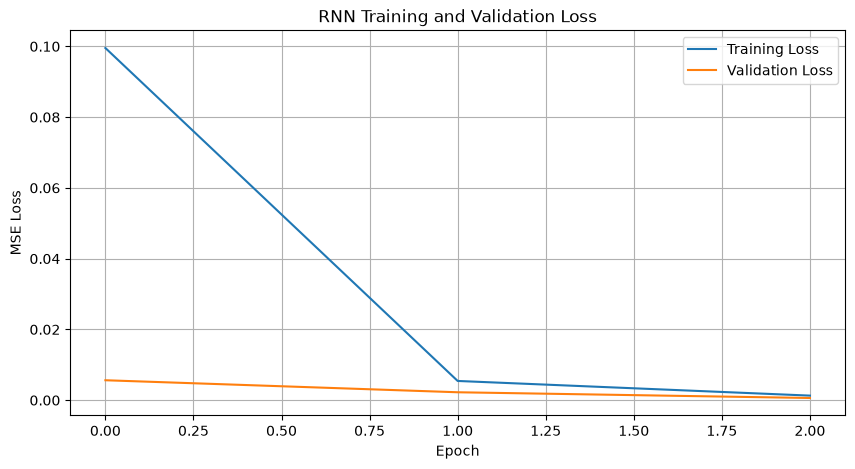

In [26]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("RNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()


In [27]:
test_loss, test_mae = model.evaluate(X_test, y_test, verbose=0)

print("Test MSE:", round(test_loss, 6))
print("Test MAE:", round(test_mae, 6))


Test MSE: 0.000649
Test MAE: 0.023114


In [28]:
y_pred = model.predict(X_test, verbose=0).flatten()

print("First 10 actual values:")
print(y_test[:10])

print("\nFirst 10 predicted values:")
print(y_pred[:10])


First 10 actual values:
[-0.95841889 -0.92514181 -0.88262103 -0.83128139 -0.77163586 -0.70428039
 -0.62988799 -0.54920196 -0.46302849 -0.37222858]

First 10 predicted values:
[-0.9258976  -0.8825307  -0.8380457  -0.79168844 -0.7418451  -0.6868899
 -0.625537   -0.5569272  -0.4806256  -0.396616  ]


In [29]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("Mean Squared Error (MSE):", round(mse, 6))
print("Mean Absolute Error (MAE):", round(mae, 6))


Mean Squared Error (MSE): 0.000649
Mean Absolute Error (MAE): 0.023114


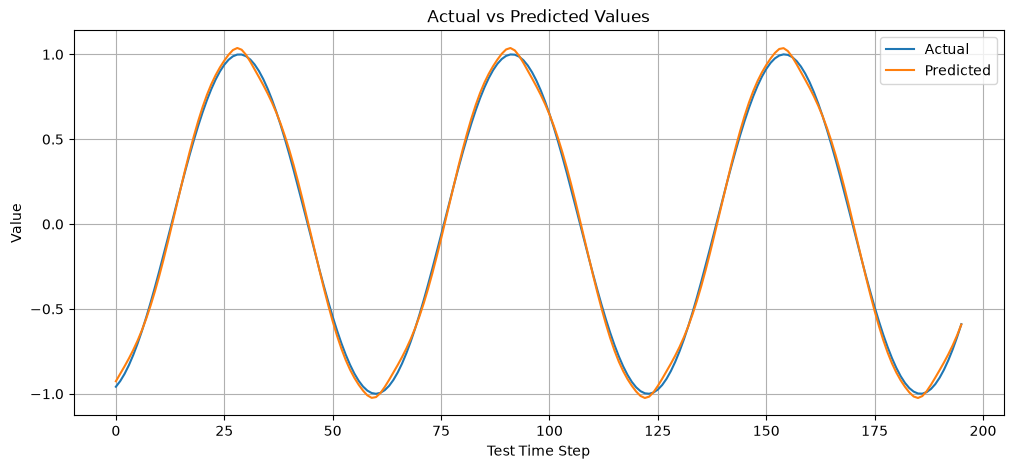

In [30]:
plt.figure(figsize=(12, 5))
plt.plot(y_test[:300], label="Actual")
plt.plot(y_pred[:300], label="Predicted")
plt.title("Actual vs Predicted Values")
plt.xlabel("Test Time Step")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.show()


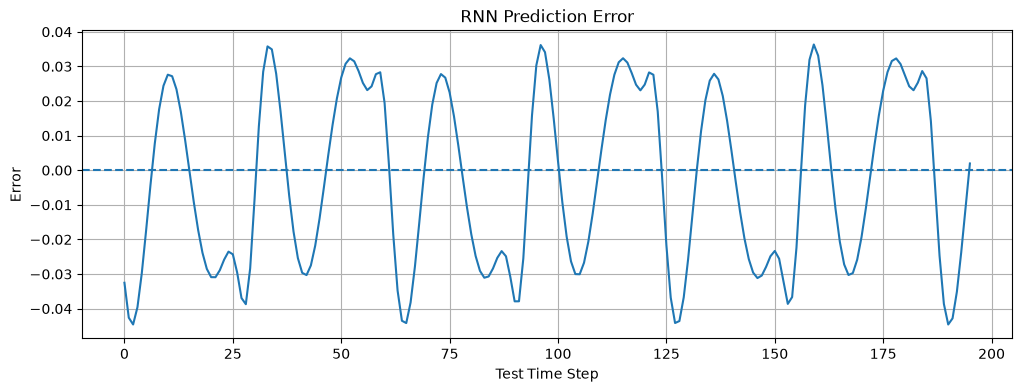

In [31]:
errors = y_test - y_pred

plt.figure(figsize=(12, 4))
plt.plot(errors[:300])
plt.axhline(0, linestyle="--")
plt.title("RNN Prediction Error")
plt.xlabel("Test Time Step")
plt.ylabel("Error")
plt.grid(True)
plt.show()


In [32]:
print("=" * 60)
print("RNN SEQUENCE PREDICTION EXPERIMENT COMPLETED")
print("=" * 60)
print("Test MSE :", round(mse, 6))
print("Test MAE :", round(mae, 6))
print("Sequence length:", sequence_length)
print("The RNN learned temporal patterns from the time-series data.")


RNN SEQUENCE PREDICTION EXPERIMENT COMPLETED
Test MSE : 0.000649
Test MAE : 0.023114
Sequence length: 20
The RNN learned temporal patterns from the time-series data.
